**Loading the data**  
The sessions sheets were loaded from the raw Excel workbook (294,024 rows). The raw file is read from the Kaggle dataset and is never modified. The session timestamp was converted to a datetime type for time-based grouping.

In [1]:
import pandas as pd 
sessions = pd.read_excel('/kaggle/input/datasets/sanyazuberi/ev-charging-raw-dataset/Copy of ev_charging_dataset.xlsx', sheet_name='sessions')

sessions['start_timestamp'] = pd.to_datetime(sessions['start_timestamp'])

**Setting the timestamp as the index**  
start_timestamp was set as the index of a new DataFrame (session_ts), which pandas needs to group rows into time periods. The original sessions table is left unchanged.

In [2]:
sessions_ts = sessions.set_index('start_timestamp')

**Hourly demand and revenue**  
Sessions were grouped into hourly buckets, extending the Task 1 demand table with a revenue column. Revenue is defined as total_cost, summed per hour, alongside session count and total energy (kWh).

In [3]:
hourly_demand = sessions_ts.resample('h').agg(
    session_count = ('session_id', 'count'),
    total_energy_kwh = ('energy_kwh', 'sum'),
    total_revenue = ('total_cost', 'sum')
)

**Daily demand and revenue**  
The same aggregation was repeated at daily resolution. The forecast in this task is built from the daily series.

In [4]:
daily_demand = sessions_ts.resample('D').agg(
    session_count = ('session_id', 'count'),
    total_energy_kwh = ('energy_kwh', 'sum'),
    total_revenue = ('total_cost', 'sum')
)

**Average price in kWh**  
Average price is revenue divided by energy delivered, which is the energy-weighted price that exactly reproduces total revenue. In hours with no sessions, both values are zero, so the price is undefined and left missing rather than filled with a value.

In [5]:
hourly_demand['avg_price_per_kwh'] = hourly_demand['total_revenue'] / hourly_demand['total_energy_kwh']
daily_demand['avg_price_per_kwh'] = daily_demand['total_revenue'] / daily_demand['total_energy_kwh']

**Building the daily revenue table**  
This is the main dataset for the task. Each day includes sessions, energy, revenue, active stations, and average price. Active stations are included because the network grew from 8 to 17 to 33 stations, so total revenue mixes network size with customer behavior. The per-station columns (kwh_per_station, revenue_per_station) separate the two.

In [6]:
s = sessions.copy()
s['date'] = s['start_timestamp'].dt.normalize()

daily_rev = s.groupby('date').agg(
    session_count=('session_id', 'count'),
    total_energy_kwh=('energy_kwh', 'sum'),
    total_revenue=('total_cost', 'sum'),
    active_stations=('station_id', 'nunique'),
)
daily_rev['avg_price_per_kwh'] = daily_rev['total_revenue'] / daily_rev['total_energy_kwh']
daily_rev['kwh_per_station'] = daily_rev['total_energy_kwh'] / daily_rev['active_stations']
daily_rev['revenue_per_station'] = daily_rev['total_revenue'] / daily_rev['active_stations']

print(len(daily_rev))
print(daily_rev.groupby(daily_rev.index.year)['active_stations'].agg(['min', 'max']))

1096
      min  max
date          
2022    8    8
2023   17   17
2024   33   33


The table has 1,096 rows (365 + 365 + 366), so no days are missing. Active stations are constant within each year (8,17 and 33), which means dividing bby station count is valid.

**Sessions per station and saving the revenue dataset**  
Sessions per station-day was added as a demand measure unaffected by network size. The revenue time-series dataset was then saved as a CSV.

In [7]:
daily_rev['sessions_per_station'] = daily_rev['session_count'] / daily_rev['active_stations']
daily_rev.to_csv('/kaggle/working/daily_revenue.csv')

**Price elasticity: how price is structured**  
Elasticity can only be estimated from price variation that is independent of other demand drivers, so the structure of price was checked first.   
Sessions were split into peak (16:00-20:59) and off-peak, and price was summarised by year and period. Separate checks showed that price does not differ by charger type, user type, payment method, or day of the week; regional differences disappear once year is controlled (several regions had no stations in 2022).

In [8]:
s = sessions.copy()
s['peak'] = s['start_timestamp'].dt.hour.between(16, 20)
print(s.groupby(['year', 'peak'])['price_per_kwh'].agg(['mean', 'std']).round(3))


             mean    std
year peak               
2022 False  0.500  0.029
     True   0.551  0.035
2023 False  0.625  0.043
     True   0.687  0.051
2024 False  0.575  0.044
     True   0.632  0.051


Price has two systematic components. The first is a yearly base level: off-peak averages were £0.500, £0.625, and £0.575 in 2022, 2023, and 2024, a 25% rise followed by an 8% fall. The second is a peak premium of almost exactly 105 in every year (£0.551 vs £0.500, £0.687 vs £0.625, £0.632 vs £0.575).  
Because the premium is identical each year and always at the same hours, it adds no variation beyond hour of day. Prices still vary by about 3-5p within each year and period (standard deviation 0.029-0.051).

**Price elasticity: session-level response**  
Th year and peak-hour effects were removed from each session's price, leaving only the unexplained variation. That residual was then correlated with energy per session and with session duration to see whether behaviour responds to price at session level.

In [9]:
s['price_resid'] = s['price_per_kwh'] - s.groupby(['year', 'peak'])['price_per_kwh'].transform('mean')
print(s[['price_resid', 'energy_kwh', 'session_duration_minutes']].corr().loc['price_resid'].round(4))

price_resid                 1.0000
energy_kwh                 -0.0016
session_duration_minutes    0.0005
Name: price_resid, dtype: float64


The correlations are effectively zero: -0.0016 with energy per session and + 0.0005 with duration. At session level, no response to price is detectable.

**Price elasticity: year-level comparison**  
The only remaining price variation is the yearly steps, and those coincide with network growth, so total demand cannot be compared across years.   
Demand per station was used instead. Arc elasticity between conservative years is the percentage change in kWh per station-day divided by the percentage change in price.

In [10]:
yearly = daily_rev.groupby(daily_rev.index.year).agg(
    stations=('active_stations', 'first'),
    sessions_per_station_day=('sessions_per_station', 'mean'),
    kwh_per_station_day=('kwh_per_station', 'mean'),
    total_revenue=('total_revenue', 'sum'),
    total_energy_kwh=('total_energy_kwh', 'sum'),
)
yearly['avg_price'] = yearly['total_revenue'] / yearly['total_energy_kwh']
pct = yearly[['kwh_per_station_day', 'avg_price']].pct_change()
yearly['arc_elasticity'] = pct['kwh_per_station_day'] / pct['avg_price']
print(yearly.round(3))

      stations  sessions_per_station_day  kwh_per_station_day  total_revenue  \
date                                                                           
2022         8                    13.918              688.982     1028771.80   
2023        17                    13.881              652.558     2587773.92   
2024        33                    13.848              641.480     4554554.40   

      total_energy_kwh  avg_price  arc_elasticity  
date                                               
2022         2011828.0      0.511             NaN  
2023         4049124.5      0.639          -0.212  
2024         7747793.3      0.588           0.212  


Sessions per station-day were essentially flat (13.918, 13.881, 13.848), while price rose 25% and then fell 8%. The two elasticities are -0.21 (2022 to 2023) and +0.21 (2023 to 2024). The opposite signs mean the price response is inconsistent, so the estimate is effectively zero. kWh per station-day drifts down (689, 653, 641) regardless of price direction, mainly due to lower energy per station, and this drift has not been diagnosed.

**Limitation:** This rests on three price levels, and the dataset appears simulated (flat monthly seasonality, durations capped at 15-60 minutes). A measured zero may reflect how the data was generated, not how real customers behave.

**Forecast model: design and validation split**  
One forecasting model was required, and I chose Prophet because it handles trend and weekly seasonality directly. Since revenue = stations * kWh per station-day * price, only the unpredictable part, daily kWh per station, is modeled. Stations and price are explicit assumptions, so the model does not extrapolate network expansion or price steps as if they were a trend. The last 90 days were held out as a chronological test set. I ran Prophet on its default settings to see whether the data show yearly seasonality.

1006 90


14:26:14 - cmdstanpy - INFO - Chain [1] start processing
14:26:14 - cmdstanpy - INFO - Chain [1] done processing


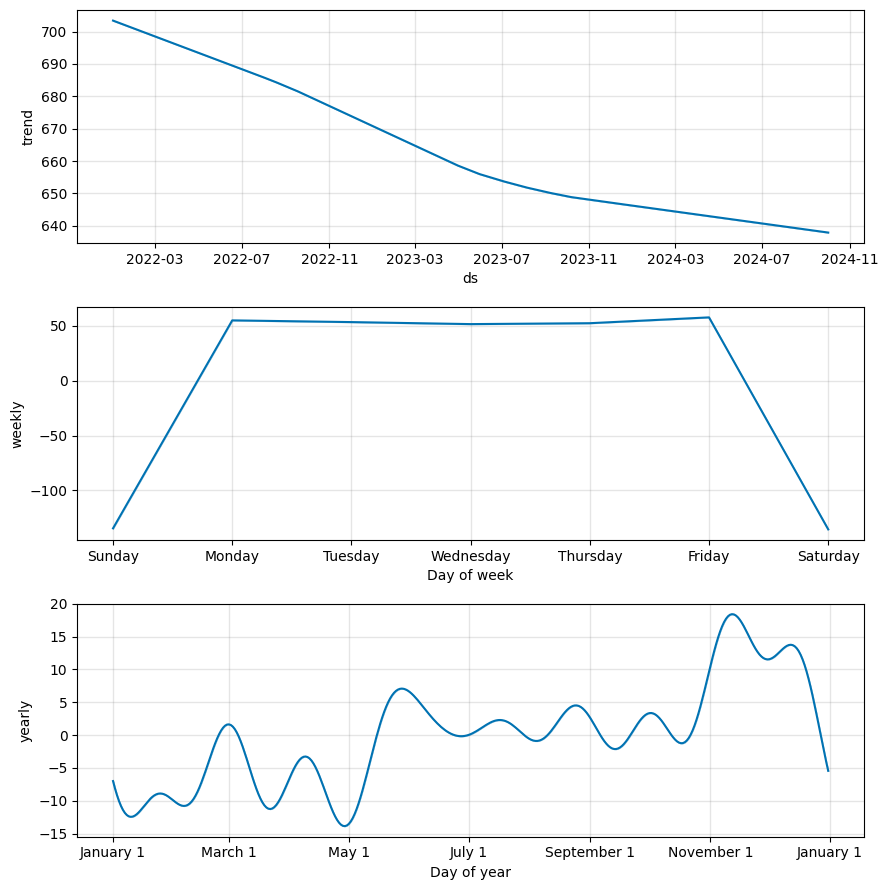

In [11]:
from prophet import Prophet
from sklearn.metrics import root_mean_squared_error, mean_absolute_percentage_error

model_df = daily_rev[['kwh_per_station']].reset_index().rename(columns={'date': 'ds', 'kwh_per_station': 'y'})

cutoff = model_df['ds'].max() - pd.Timedelta(days=90)
train_p = model_df[model_df['ds'] <= cutoff]
test_p = model_df[model_df['ds'] > cutoff]
print(len(train_p), len(test_p))   

m = Prophet()   
m.fit(train_p)
fc = m.predict(test_p[['ds']])
m.plot_components(m.predict(train_p[['ds']]));

The split gives 1,006 training days and 90 test days. All test days have 33 stations, so network growth doesn't affect the test.   

**Component plot**  
**Trend:** declines gently from about 703 to 638 kWh per station-day and flattens over time, matching the per-station drift seen earlier.  
**Weekly:** weekdays sit about -50 to +58 kWh above the level and weekends about -135 below it, a swing of roughly 190 kWh. This matches the roughly 27% weekday/weekend gap found in Task 1.  
**Yearly:** small (about +-15 on a level near 640, around 2-3%) and irregular, with run of small bumps and no plausible physical cause. With under three years of training data, it looks like fitted noise.

 **Forecast model: validation on the held-out 90 days**  
I measured error on the demand model, then converted it to revenue by multiplying predicted kWh by the number of stations and the actual price in the test window. Using the actual price isolated the demand model's accuracy. MAPE is safe to use here  because daily values are never zero.

In [12]:
# Demand model: kWh per station-day
print('RMSE:', root_mean_squared_error(test_p['y'], fc['yhat']))
print('MAPE:', mean_absolute_percentage_error(test_p['y'], fc['yhat']))

# Revenue: predicted kWh x stations x the ACTUAL price in the test window
test_eval = daily_rev.loc[test_p['ds']].copy()
test_eval['pred_revenue'] = fc['yhat'].values * test_eval['active_stations'] * test_eval['avg_price_per_kwh']

print('Revenue MAPE (daily):', mean_absolute_percentage_error(test_eval['total_revenue'], test_eval['pred_revenue']))

monthly = test_eval[['total_revenue', 'pred_revenue']].resample('MS').sum()
monthly['pct_error'] = (monthly['pred_revenue'] / monthly['total_revenue'] - 1) * 100
print(monthly.round(0))

RMSE: 30.76406574658938
MAPE: 0.037636475027239276
Revenue MAPE (daily): 0.03763647502723929
            total_revenue  pred_revenue  pct_error
date                                              
2024-10-01       360834.0      360503.0       -0.0
2024-11-01       370663.0      377250.0        2.0
2024-12-01       387844.0      386965.0       -0.0


RMSE is 30.8kWh per station-day (about 5% of the typical level), and MAPE is 3.8%. The revenue MAPE is identical to the demand MAPE because, with the actual price used, actual revenue is exactly actual kWh * station * price. It is reported once as demand model accuracy and is not a separate validation of revenue. Monthly errors over the test window are -0.09% (Oct), +1.78%(Nov), and -0.23% (Dec). With only three months, the daily metrics are the reliable measure.

**Forecast model: testing yearly seasonality**  
I refit the model without yearly seasonality on the same split so I can compare the two versions directly. The decision rule was set before seeing the result: drop yearly seasonality if the simpler version performs equally well.

In [13]:
m2 = Prophet(yearly_seasonality=False)
m2.fit(train_p)
fc2 = m2.predict(test_p[['ds']])

print('With yearly    - RMSE:', round(root_mean_squared_error(test_p['y'], fc['yhat']), 2),
      'MAPE:', round(mean_absolute_percentage_error(test_p['y'], fc['yhat']), 4))
print('Without yearly - RMSE:', round(root_mean_squared_error(test_p['y'], fc2['yhat']), 2),
      'MAPE:', round(mean_absolute_percentage_error(test_p['y'], fc2['yhat']), 4))

test_eval['pred_revenue_noyear'] = fc2['yhat'].values * test_eval['active_stations'] * test_eval['avg_price_per_kwh']
monthly2 = test_eval[['total_revenue', 'pred_revenue', 'pred_revenue_noyear']].resample('MS').sum()
monthly2['err_with_yearly_%'] = (monthly2['pred_revenue'] / monthly2['total_revenue'] - 1) * 100
monthly2['err_no_yearly_%'] = (monthly2['pred_revenue_noyear'] / monthly2['total_revenue'] - 1) * 100
print(monthly2.round({'total_revenue': 0, 'pred_revenue': 0, 'pred_revenue_noyear': 0,
                      'err_with_yearly_%': 2, 'err_no_yearly_%': 2}))

14:26:16 - cmdstanpy - INFO - Chain [1] start processing
14:26:17 - cmdstanpy - INFO - Chain [1] done processing


With yearly    - RMSE: 30.76 MAPE: 0.0376
Without yearly - RMSE: 30.41 MAPE: 0.038
            total_revenue  pred_revenue  pred_revenue_noyear  \
date                                                           
2024-10-01       360834.0      360503.0             358592.0   
2024-11-01       370663.0      377250.0             367518.0   
2024-12-01       387844.0      386965.0             380699.0   

            err_with_yearly_%  err_no_yearly_%  
date                                            
2024-10-01              -0.09            -0.62  
2024-11-01               1.78            -0.85  
2024-12-01              -0.23            -1.84  


The metrics are effectively tied, so I dropped yearly seasonality as the simpler option. This agrees with the flat monthly averages in Task 1 and the short history available. Monthly errors are mixed: with yearly seasonality, -0.09%, +1.78%, -0.23%; without it, -0.62%, -0.85%, -7.84%. The test windows cover only October to December, so it cannot speak to other months. The chosen model runs slightly low (under 2%) over this window.

**Final model and forecast setup**  
I refit the model on all 1,096 days and used it to forecast 365 days of 2025. Two baseline assumptions are set explicitly: 33 stations (the 2024 network) and the 2024 average price.

In [14]:
m_final = Prophet(yearly_seasonality=False)
m_final.fit(model_df)                      # all 1,096 days
fc_final = m_final.predict(m_final.make_future_dataframe(periods=365, freq='D')).tail(365)

STATIONS_2025 = 33
PRICE_2025 = daily_rev.loc['2024', 'total_revenue'].sum() / daily_rev.loc['2024', 'total_energy_kwh'].sum()
print(len(fc_final), fc_final['ds'].min().date(), fc_final['ds'].max().date(), round(PRICE_2025, 4))

14:26:17 - cmdstanpy - INFO - Chain [1] start processing
14:26:17 - cmdstanpy - INFO - Chain [1] done processing


365 2025-01-01 2025-12-31 0.5879


The forecast covers 365 days from 2025-01-01 to 2025-12-31. The baseline price is £0.588/kWh.

**2025 baseline revenue forecast**  
revenue_path converts the forecast into revenue (predicted kWh per station * stations * price) and can also apply a price change and elasticity, as the scenarios below do. With no price change, it gives the baseline, aggregated to months.

In [15]:
def revenue_path(price_change=0.0, elasticity=0.0):
    price = PRICE_2025 * (1 + price_change)
    kwh_per_station = fc_final['yhat'].values * (1 + price_change) ** elasticity
    return pd.Series(kwh_per_station * STATIONS_2025 * price, index=pd.to_datetime(fc_final['ds']))

baseline_monthly = revenue_path().resample('MS').sum()
print(baseline_monthly.round(0))
print('2025 baseline total:', round(baseline_monthly.sum()))

ds
2025-01-01    387045.0
2025-02-01    346470.0
2025-03-01    379094.0
2025-04-01    372680.0
2025-05-01    382158.0
2025-06-01    368426.0
2025-07-01    385084.0
2025-08-01    377586.0
2025-09-01    371158.0
2025-10-01    384206.0
2025-11-01    363230.0
2025-12-01    383532.0
Freq: MS, dtype: float64
2025 baseline total: 4500670


The 2025 baseline is £4.50M, about 1.2% below 2024 (£4.55M). About 0.3 points of that come from 2025 having one fewer day, and the rest from the gentle decline in per-station demand. The monthly pattern is calendar composition, not yearly seasonality: February is short, and August and November have 10 weekend days against 8 in January, April, and July, so their revenue per day is lowest.

**Price scenarios (+5%, -10%)**  
In each scenario, demand scales by (1 + price change)^ε, and revenue is demand * price. The measured elasticity (about zero) is the base case. The other values (-0.5, -1.0, -1.5) are assumptions, shown as sensitivity, not findings.

In [16]:
rows = []
for eps in [0, -0.5, -1.0, -1.5]:
    base = revenue_path(0, eps).sum()
    for name, dp in [('+5%', 0.05), ('-10%', -0.10)]:
        scen = revenue_path(dp, eps).sum()
        rows.append({'elasticity': eps, 'scenario': name,
                     'annual_revenue': round(scen), 'change_vs_baseline_%': round((scen / base - 1) * 100, 1)})
scenarios = pd.DataFrame(rows)
print(scenarios)

   elasticity scenario  annual_revenue  change_vs_baseline_%
0         0.0      +5%         4725703                   5.0
1         0.0     -10%         4050603                 -10.0
2        -0.5      +5%         4611814                   2.5
3        -0.5     -10%         4269710                  -5.1
4        -1.0      +5%         4500670                   0.0
5        -1.0     -10%         4500670                   0.0
6        -1.5      +5%         4392204                  -2.4
7        -1.5     -10%         4744122                   5.4


Break-even is at ε=-1: with demand less price-sensitive than that, a price rise increases revenue, and with more sensitivity, it reduces it. This dataset cannot say which side real customers fall on.  
Network size is the larger lever: at baseline, each station earns about £136k a year, so a 5% price rise at zero elasticity (£225k) is worth roughly 1.65 stations.

**Saving outputs**  
I saved the monthly baseline forecast and the scenario table for use in the deliverables.

In [17]:
baseline_monthly.rename('baseline_revenue').to_csv('/kaggle/working/monthly_revenue_forecast.csv')
scenarios.to_csv('/kaggle/working/price_scenarios.csv', index=False)